PHASE 5 - SHAP ANALYSIS

Project directory:
c:\Users\mvars\Downloads\open_lab

SHAP output directory:
c:\Users\mvars\Downloads\open_lab\outputs\shap_analysis

CHECKING REQUIRED FILES

Processed directory:
c:\Users\mvars\Downloads\open_lab\data\processed

Model directory:
c:\Users\mvars\Downloads\open_lab\models

Required directories found.

SEARCHING FOR SUSCEPTIBILITY MODEL

Available model files:
 - c:\Users\mvars\Downloads\open_lab\models\exposure_best_model.joblib
 - c:\Users\mvars\Downloads\open_lab\models\exposure_imputer.joblib
 - c:\Users\mvars\Downloads\open_lab\models\exposure_random_forest.joblib
 - c:\Users\mvars\Downloads\open_lab\models\exposure_xgboost.joblib
 - c:\Users\mvars\Downloads\open_lab\models\exposure_xgboost.pkl
 - c:\Users\mvars\Downloads\open_lab\models\feature_information.pkl
 - c:\Users\mvars\Downloads\open_lab\models\phase3_all_models.pkl
 - c:\Users\mvars\Downloads\open_lab\models\susceptibility_best_model.joblib
 - c:\Users\mvars\Downloads\open_lab\mode

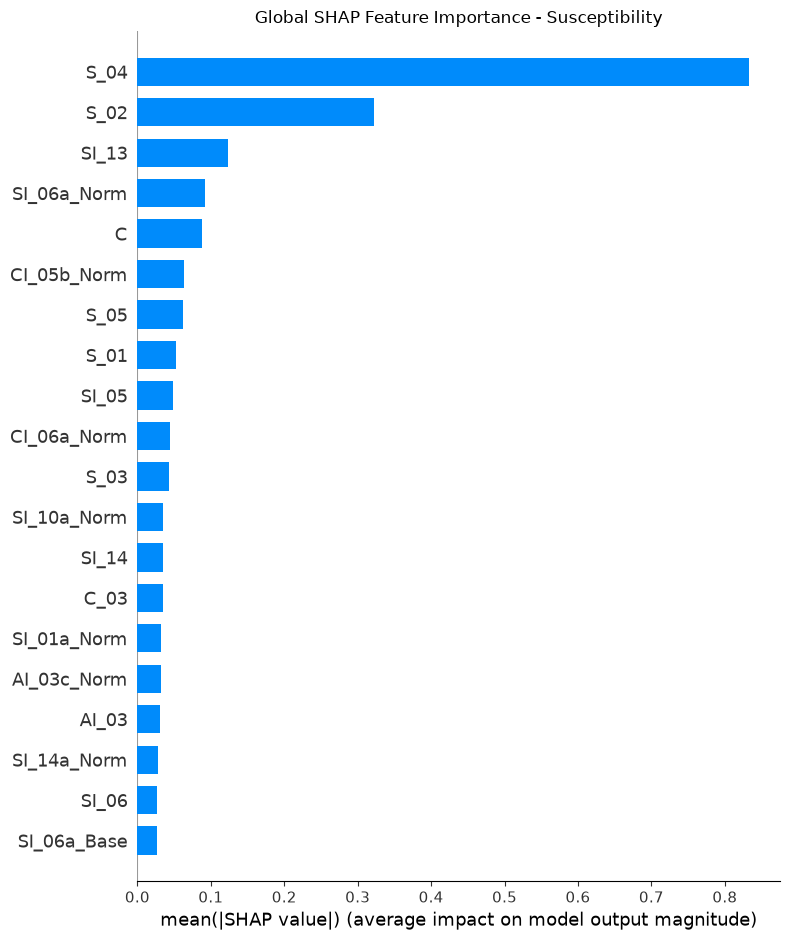


Bar plot saved to:
c:\Users\mvars\Downloads\open_lab\outputs\shap_analysis\susceptibility_shap_summary_bar.png

CREATING SHAP SUMMARY PLOT


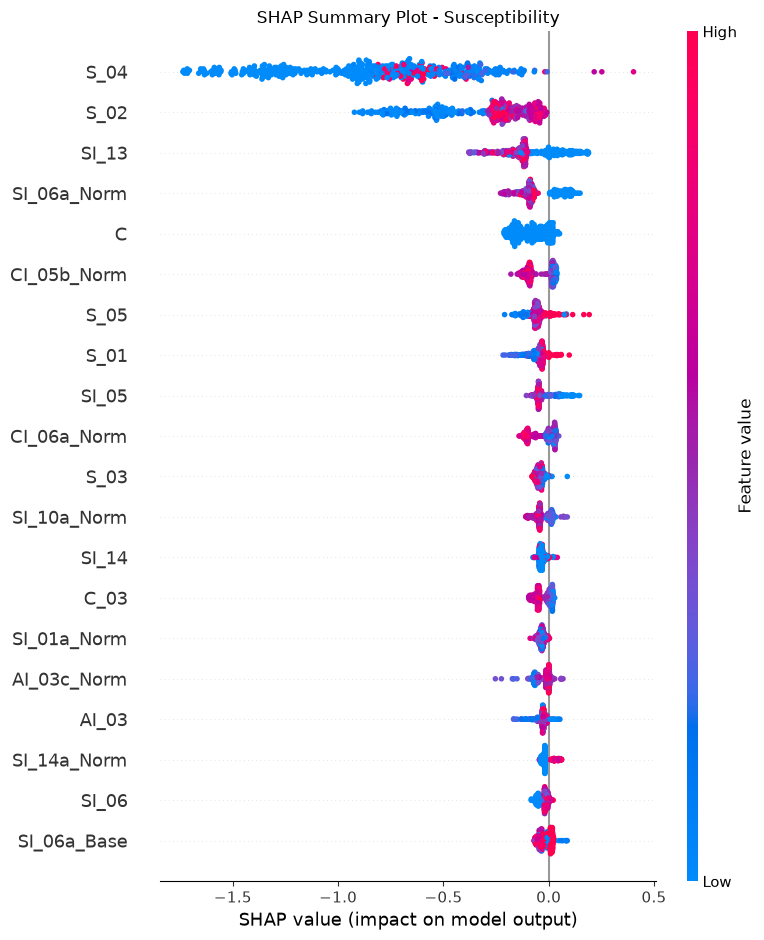


Summary plot saved to:
c:\Users\mvars\Downloads\open_lab\outputs\shap_analysis\susceptibility_shap_summary.png

CREATING SHAP DEPENDENCE PLOTS

Top features selected for dependence plots:
 - S_04
 - S_02
 - SI_13
 - SI_06a_Norm
 - S_05

Creating dependence plot 1 of 5 : S_04


<Figure size 1000x700 with 0 Axes>

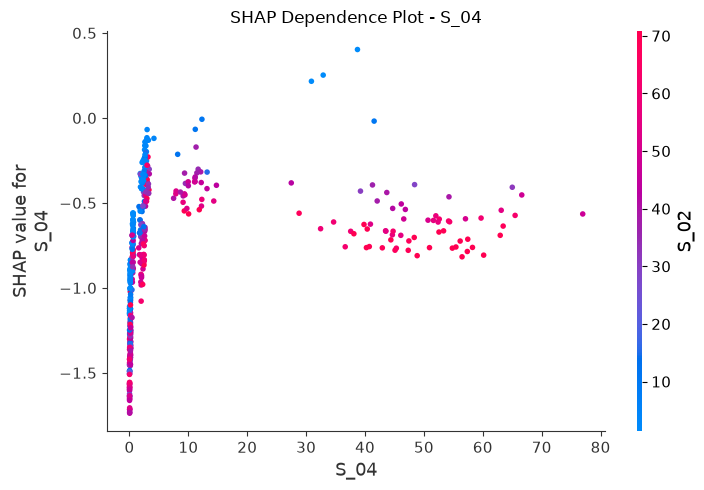

Saved: c:\Users\mvars\Downloads\open_lab\outputs\shap_analysis\dependence_1_S_04.png

Creating dependence plot 2 of 5 : S_02


<Figure size 1000x700 with 0 Axes>

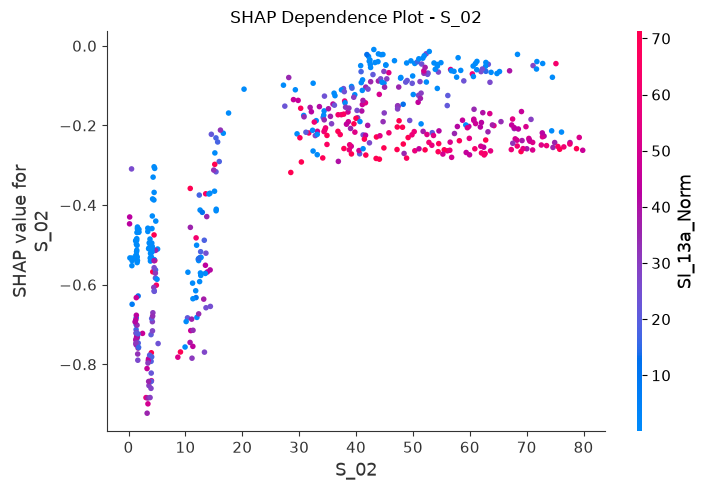

Saved: c:\Users\mvars\Downloads\open_lab\outputs\shap_analysis\dependence_2_S_02.png

Creating dependence plot 3 of 5 : SI_13


<Figure size 1000x700 with 0 Axes>

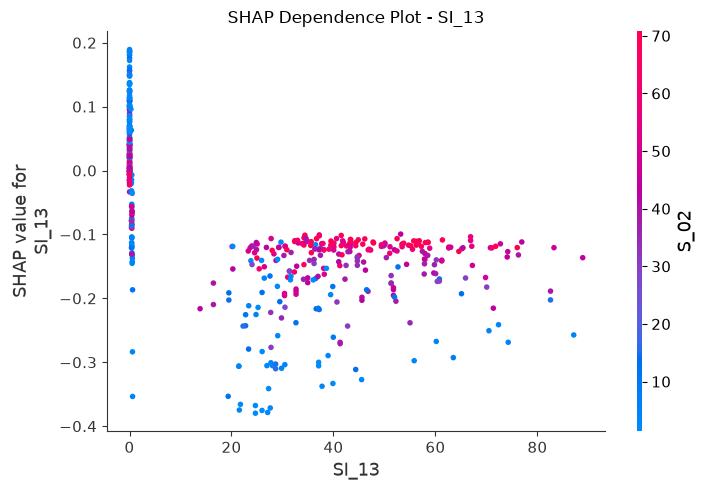

Saved: c:\Users\mvars\Downloads\open_lab\outputs\shap_analysis\dependence_3_SI_13.png

Creating dependence plot 4 of 5 : SI_06a_Norm


<Figure size 1000x700 with 0 Axes>

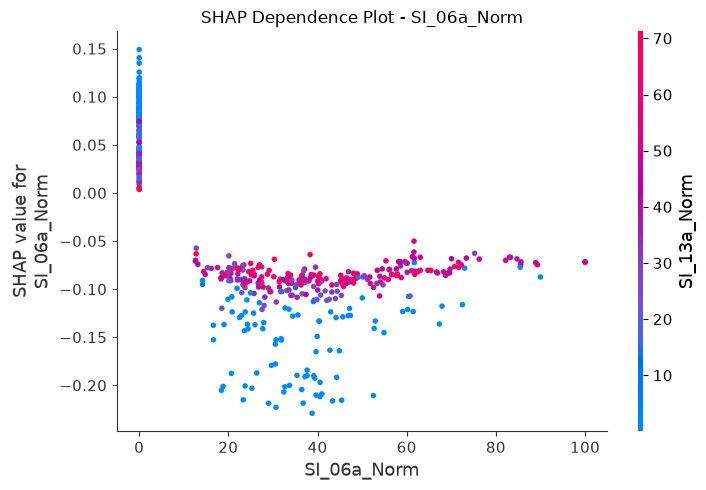

Saved: c:\Users\mvars\Downloads\open_lab\outputs\shap_analysis\dependence_4_SI_06a_Norm.png

Creating dependence plot 5 of 5 : S_05


<Figure size 1000x700 with 0 Axes>

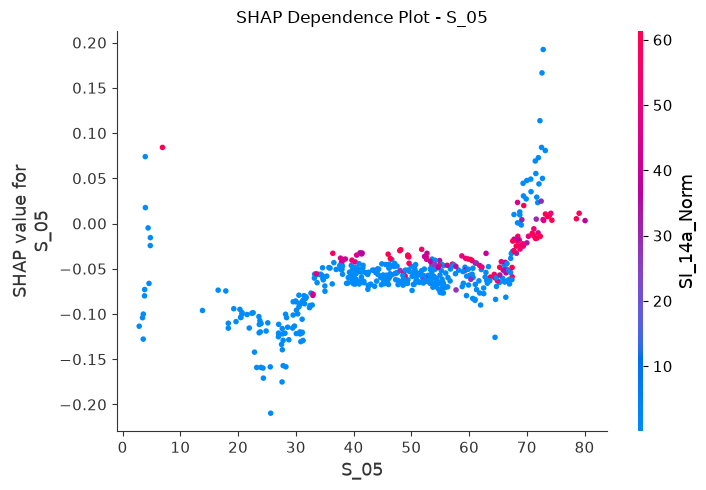

Saved: c:\Users\mvars\Downloads\open_lab\outputs\shap_analysis\dependence_5_S_05.png

TOP SHAP FEATURES

Top 20 feature table saved to:
c:\Users\mvars\Downloads\open_lab\outputs\shap_analysis\top_20_susceptibility_shap_features.csv

Top 20 features:
 Rank     Feature  Mean_Absolute_SHAP
    1        S_04            1.607688
    2        S_02            0.605313
    3       SI_13            0.205561
    4 SI_06a_Norm            0.130619
    5        S_05            0.104908
    6           C            0.097545
    7        S_01            0.092535
    8       SI_14            0.087765
    9 CI_05b_Norm            0.072010
   10       SI_05            0.070162
   11        S_03            0.069588
   12 SI_13a_Base            0.064788
   13 SI_13a_Norm            0.060787
   14       SI_06            0.059637
   15 SI_06a_Base            0.054455
   16 SI_10a_Norm            0.051489
   17 AI_03c_Norm            0.049399
   18 CI_06a_Norm            0.049273
   19       AI_03           

In [ ]:

import os
import warnings

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import shap

warnings.filterwarnings("ignore")

print("=" * 70)
print("PHASE 5 - SHAP ANALYSIS")
print("=" * 70)


# ============================================================
# 2. DEFINE PATHS
# ============================================================

# Notebook is inside:
# open_lab/notebooks/

# Therefore ../ means:
# open_lab/

PROJECT_DIR = os.path.abspath("..")

DATA_DIR = os.path.join(PROJECT_DIR, "data")
PROCESSED_DIR = os.path.join(DATA_DIR, "processed")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")

OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "outputs",
    "shap_analysis"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("\nProject directory:")
print(PROJECT_DIR)

print("\nSHAP output directory:")
print(OUTPUT_DIR)


# ============================================================
# 3. CHECK REQUIRED FILES
# ============================================================

print("\n" + "=" * 70)
print("CHECKING REQUIRED FILES")
print("=" * 70)

print("\nProcessed directory:")
print(PROCESSED_DIR)

print("\nModel directory:")
print(MODEL_DIR)

if not os.path.exists(PROCESSED_DIR):
    raise FileNotFoundError(
        "Processed data directory was not found:\n"
        + PROCESSED_DIR
    )

if not os.path.exists(MODEL_DIR):
    raise FileNotFoundError(
        "Models directory was not found:\n"
        + MODEL_DIR
    )

print("\nRequired directories found.")


# ============================================================
# 4. FIND THE SUSCEPTIBILITY MODEL
# ============================================================

print("\n" + "=" * 70)
print("SEARCHING FOR SUSCEPTIBILITY MODEL")
print("=" * 70)

model_files = []

for root, dirs, files in os.walk(MODEL_DIR):
    for file in files:
        if file.lower().endswith((".pkl", ".joblib")):
            model_files.append(
                os.path.join(root, file)
            )

print("\nAvailable model files:")

for file in model_files:
    print(" -", file)


# Try to identify susceptibility model automatically
susceptibility_model_path = None

for file in model_files:

    name = os.path.basename(file).lower()

    if "susceptibility" in name:
        susceptibility_model_path = file
        break


# If not found, search for xgboost + susceptibility
if susceptibility_model_path is None:

    for file in model_files:

        name = os.path.basename(file).lower()

        if "xgb" in name and "sus" in name:
            susceptibility_model_path = file
            break


if susceptibility_model_path is None:

    raise FileNotFoundError(
        "\nCould not automatically find the Susceptibility model.\n"
        "Please check the models folder.\n"
        "Available files:\n"
        + "\n".join(model_files)
    )


print("\nSusceptibility model:")
print(susceptibility_model_path)


# ============================================================
# 5. LOAD SUSCEPTIBILITY MODEL
# ============================================================

print("\n" + "=" * 70)
print("LOADING SUSCEPTIBILITY MODEL")
print("=" * 70)

susceptibility_model = joblib.load(
    susceptibility_model_path
)

print("\nModel loaded successfully.")

print("\nModel type:")
print(type(susceptibility_model))


# ============================================================
# 6. LOAD TEST FEATURES
# ============================================================

print("\n" + "=" * 70)
print("LOADING TEST FEATURES")
print("=" * 70)


# Search for X_test file
possible_x_test = [
    os.path.join(PROCESSED_DIR, "X_test.csv"),
    os.path.join(PROCESSED_DIR, "x_test.csv"),
    os.path.join(PROCESSED_DIR, "X_test_processed.csv"),
    os.path.join(PROCESSED_DIR, "x_test_processed.csv"),
]


X_test_path = None

for path in possible_x_test:

    if os.path.exists(path):
        X_test_path = path
        break


# If exact name wasn't found, search automatically
if X_test_path is None:

    for file in os.listdir(PROCESSED_DIR):

        lower = file.lower()

        if (
            "x_test" in lower
            and lower.endswith(".csv")
        ):
            X_test_path = os.path.join(
                PROCESSED_DIR,
                file
            )
            break


if X_test_path is None:

    raise FileNotFoundError(
        "\nCould not find X_test CSV in:\n"
        + PROCESSED_DIR
    )


print("\nX_test file:")
print(X_test_path)


X_test = pd.read_csv(X_test_path)

print("\nX_test loaded successfully.")

print("Shape:", X_test.shape)


# ============================================================
# 7. LOAD TARGET INFORMATION IF AVAILABLE
# ============================================================

print("\n" + "=" * 70)
print("CHECKING TARGET DATA")
print("=" * 70)


possible_y_test = [
    os.path.join(
        PROCESSED_DIR,
        "y_test_susceptibility.csv"
    ),
    os.path.join(
        PROCESSED_DIR,
        "y_test_susceptibility_category.csv"
    ),
    os.path.join(
        PROCESSED_DIR,
        "y_test.csv"
    ),
]


y_test_path = None

for path in possible_y_test:

    if os.path.exists(path):
        y_test_path = path
        break


if y_test_path is not None:

    print("\nFound y_test:")
    print(y_test_path)

    y_test = pd.read_csv(y_test_path)

    print("y_test shape:", y_test.shape)

else:

    print(
        "\nNo y_test susceptibility file found."
    )

    y_test = None


# ============================================================
# 8. CLEAN X_TEST
# ============================================================

print("\n" + "=" * 70)
print("PREPARING FEATURES")
print("=" * 70)


# Remove accidental index columns
index_columns = []

for column in X_test.columns:

    if (
        str(column).lower().startswith("unnamed")
        or str(column).lower() in ["index"]
    ):
        index_columns.append(column)


if index_columns:

    print("\nRemoving index columns:")
    print(index_columns)

    X_test = X_test.drop(
        columns=index_columns
    )


# Keep only numeric columns
numeric_columns = X_test.select_dtypes(
    include=[np.number]
).columns.tolist()


if len(numeric_columns) != len(X_test.columns):

    non_numeric = [
        c for c in X_test.columns
        if c not in numeric_columns
    ]

    print("\nRemoving non-numeric columns:")
    print(non_numeric)

    X_test = X_test[numeric_columns]


print("\nFinal X_test shape:")
print(X_test.shape)


# ============================================================
# 9. MATCH MODEL FEATURES
# ============================================================

print("\n" + "=" * 70)
print("MATCHING MODEL FEATURES")
print("=" * 70)


# Some sklearn/XGBoost models store feature names.
model_features = None

try:

    if hasattr(
        susceptibility_model,
        "feature_names_in_"
    ):

        model_features = list(
            susceptibility_model.feature_names_in_
        )

except Exception:
    model_features = None


# XGBoost Booster can also contain feature names
if model_features is None:

    try:

        if hasattr(
            susceptibility_model,
            "get_booster"
        ):

            booster = susceptibility_model.get_booster()

            if booster.feature_names is not None:

                model_features = list(
                    booster.feature_names
                )

    except Exception:
        model_features = None


if model_features is not None:

    print(
        "\nModel expects",
        len(model_features),
        "features."
    )

    available_features = [
        f for f in model_features
        if f in X_test.columns
    ]

    missing_features = [
        f for f in model_features
        if f not in X_test.columns
    ]

    if missing_features:

        print("\nWARNING:")
        print(
            "Some model features are missing from X_test:"
        )

        print(missing_features[:20])

    # Reorder columns according to model
    X_test = X_test.reindex(
        columns=model_features,
        fill_value=0
    )

else:

    print(
        "\nModel feature names could not be read."
    )

    print(
        "Using X_test columns as they are."
    )


print("\nFinal feature count:")
print(X_test.shape[1])


# ============================================================
# 10. HANDLE MISSING VALUES
# ============================================================

print("\n" + "=" * 70)
print("CHECKING MISSING VALUES")
print("=" * 70)


missing_count = X_test.isna().sum().sum()

print(
    "\nTotal missing values:",
    missing_count
)


if missing_count > 0:

    print(
        "\nReplacing missing values with "
        "column medians."
    )

    X_test = X_test.fillna(
        X_test.median(numeric_only=True)
    )

    # If anything still remains NaN
    X_test = X_test.fillna(0)


# ============================================================
# 11. SELECT A SHAP SAMPLE
# ============================================================

print("\n" + "=" * 70)
print("CREATING SHAP SAMPLE")
print("=" * 70)


# IMPORTANT:
# We don't calculate SHAP on all 1004 rows.
#
# 500 rows is enough for a useful global explanation
# and considerably faster.

SHAP_SAMPLE_SIZE = 500

actual_sample_size = min(
    SHAP_SAMPLE_SIZE,
    len(X_test)
)


# Fixed random state makes results reproducible
X_shap = X_test.sample(
    n=actual_sample_size,
    random_state=42
).copy()


print(
    "\nOriginal test samples:",
    len(X_test)
)

print(
    "SHAP samples:",
    len(X_shap)
)

print(
    "Number of features:",
    X_shap.shape[1]
)


# ============================================================
# 12. CREATE SHAP EXPLAINER
# ============================================================

print("\n" + "=" * 70)
print("CREATING SHAP EXPLAINER")
print("=" * 70)


try:

    explainer = shap.TreeExplainer(
        susceptibility_model
    )

    print(
        "\nTreeExplainer created successfully."
    )

except Exception as e:

    print(
        "\nTreeExplainer failed:"
    )

    print(e)

    print(
        "\nTrying generic SHAP Explainer..."
    )

    explainer = shap.Explainer(
        susceptibility_model,
        X_shap
    )


# ============================================================
# 13. CALCULATE SHAP VALUES
# ============================================================

print("\n" + "=" * 70)
print("CALCULATING SHAP VALUES")
print("=" * 70)

print(
    "\nThis is the main SHAP calculation."
)

print(
    "Please wait..."
)


shap_values = explainer.shap_values(
    X_shap
)


print(
    "\nSHAP values calculated successfully."
)


# ============================================================
# 14. HANDLE MULTI-CLASS SHAP OUTPUT
# ============================================================

print("\n" + "=" * 70)
print("PROCESSING SHAP OUTPUT")
print("=" * 70)


# XGBoost multiclass models can return:
#
#   list of arrays
#
# where each array corresponds to one class.
#
# Newer SHAP versions can also return:
#
#   numpy array with shape:
#   samples x features x classes


if isinstance(shap_values, list):

    print(
        "\nSHAP returned a list."
    )

    print(
        "Number of classes:",
        len(shap_values)
    )

    # Convert to numpy array
    shap_array = np.stack(
        shap_values,
        axis=-1
    )

elif isinstance(shap_values, np.ndarray):

    shap_array = shap_values

else:

    shap_array = np.asarray(
        shap_values
    )


print(
    "\nSHAP array shape:"
)

print(
    shap_array.shape
)


# ============================================================
# 15. CALCULATE GLOBAL FEATURE IMPORTANCE
# ============================================================

print("\n" + "=" * 70)
print("CALCULATING GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 70)


if shap_array.ndim == 2:

    # Binary/single-output model
    mean_abs_shap = np.mean(
        np.abs(shap_array),
        axis=0
    )

elif shap_array.ndim == 3:

    # Multiclass model
    #
    # Average absolute SHAP value over:
    #   samples
    #   classes

    mean_abs_shap = np.mean(
        np.abs(shap_array),
        axis=(0, 2)
    )

else:

    raise ValueError(
        "Unexpected SHAP array shape: "
        + str(shap_array.shape)
    )


feature_importance = pd.DataFrame({

    "Feature": X_shap.columns,

    "Mean_Absolute_SHAP":
        mean_abs_shap

})


feature_importance = (
    feature_importance
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


# Add rank
feature_importance.insert(
    0,
    "Rank",
    np.arange(
        1,
        len(feature_importance) + 1
    )
)


print("\nTop 20 SHAP features:")

print(
    feature_importance.head(20).to_string(
        index=False
    )
)


# ============================================================
# 16. SAVE FEATURE IMPORTANCE
# ============================================================

importance_path = os.path.join(
    OUTPUT_DIR,
    "susceptibility_shap_feature_importance.csv"
)


feature_importance.to_csv(
    importance_path,
    index=False
)


print(
    "\nFeature importance saved to:"
)

print(importance_path)


# ============================================================
# 17. SAVE RAW SHAP VALUES
# ============================================================

print("\n" + "=" * 70)
print("SAVING SHAP VALUES")
print("=" * 70)


# For a multiclass model, save the average absolute
# SHAP contribution across classes.
#
# This gives one SHAP value per:
#
#     sample x feature

if shap_array.ndim == 2:

    shap_for_csv = shap_array

else:

    shap_for_csv = np.mean(
        shap_array,
        axis=2
    )


shap_values_df = pd.DataFrame(
    shap_for_csv,
    columns=X_shap.columns,
    index=X_shap.index
)


shap_csv_path = os.path.join(
    OUTPUT_DIR,
    "susceptibility_shap_values.csv"
)


shap_values_df.to_csv(
    shap_csv_path,
    index=True
)


print(
    "\nSHAP values saved to:"
)

print(shap_csv_path)


# ============================================================
# 18. SAVE SHAP SAMPLE DATA
# ============================================================

sample_csv_path = os.path.join(
    OUTPUT_DIR,
    "susceptibility_shap_sample.csv"
)


X_shap.to_csv(
    sample_csv_path,
    index=True
)


print(
    "\nSHAP sample saved to:"
)

print(sample_csv_path)


# ============================================================
# 19. SHAP SUMMARY BAR PLOT
# ============================================================

print("\n" + "=" * 70)
print("CREATING SHAP BAR PLOT")
print("=" * 70)


plt.figure(
    figsize=(12, 8)
)


if shap_array.ndim == 2:

    shap.summary_plot(
        shap_array,
        X_shap,
        plot_type="bar",
        show=False
    )

else:

    # Average SHAP values across classes
    shap.summary_plot(
        shap_for_csv,
        X_shap,
        plot_type="bar",
        show=False
    )


plt.title(
    "Global SHAP Feature Importance - Susceptibility"
)

plt.tight_layout()


bar_plot_path = os.path.join(
    OUTPUT_DIR,
    "susceptibility_shap_summary_bar.png"
)


plt.savefig(
    bar_plot_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


print(
    "\nBar plot saved to:"
)

print(bar_plot_path)


# ============================================================
# 20. SHAP BEESWARM / SUMMARY PLOT
# ============================================================

print("\n" + "=" * 70)
print("CREATING SHAP SUMMARY PLOT")
print("=" * 70)


plt.figure(
    figsize=(12, 8)
)


if shap_array.ndim == 2:

    shap.summary_plot(
        shap_array,
        X_shap,
        max_display=20,
        show=False
    )

else:

    shap.summary_plot(
        shap_for_csv,
        X_shap,
        max_display=20,
        show=False
    )


plt.title(
    "SHAP Summary Plot - Susceptibility"
)

plt.tight_layout()


summary_plot_path = os.path.join(
    OUTPUT_DIR,
    "susceptibility_shap_summary.png"
)


plt.savefig(
    summary_plot_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


print(
    "\nSummary plot saved to:"
)

print(summary_plot_path)


# ============================================================
# 21. CREATE DEPENDENCE PLOTS
# ============================================================

print("\n" + "=" * 70)
print("CREATING SHAP DEPENDENCE PLOTS")
print("=" * 70)


# We only create dependence plots for the top 5 features.
#
# This prevents the notebook from producing hundreds
# of plots and keeps execution time reasonable.

TOP_N_DEPENDENCE = 5


top_features = (
    feature_importance
    .head(TOP_N_DEPENDENCE)
    ["Feature"]
    .tolist()
)


print(
    "\nTop features selected for dependence plots:"
)

for feature in top_features:
    print(" -", feature)


for rank, feature in enumerate(
    top_features,
    start=1
):

    print(
        "\nCreating dependence plot",
        rank,
        "of",
        len(top_features),
        ":",
        feature
    )

    try:

        plt.figure(
            figsize=(10, 7)
        )

        if shap_array.ndim == 2:

            shap.dependence_plot(
                feature,
                shap_array,
                X_shap,
                show=False
            )

        else:

            shap.dependence_plot(
                feature,
                shap_for_csv,
                X_shap,
                show=False
            )

        plt.title(
            "SHAP Dependence Plot - "
            + feature
        )

        plt.tight_layout()

        safe_name = (
            str(feature)
            .replace("/", "_")
            .replace("\\", "_")
            .replace(" ", "_")
            .replace(":", "_")
        )

        dependence_path = os.path.join(
            OUTPUT_DIR,
            "dependence_"
            + str(rank)
            + "_"
            + safe_name
            + ".png"
        )

        plt.savefig(
            dependence_path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

        print(
            "Saved:",
            dependence_path
        )

    except Exception as e:

        print(
            "Could not create dependence plot for",
            feature
        )

        print(e)

        plt.close()


# ============================================================
# 22. CREATE TOP FEATURES TABLE
# ============================================================

print("\n" + "=" * 70)
print("TOP SHAP FEATURES")
print("=" * 70)


top_features_table = feature_importance.head(
    20
).copy()


top_features_path = os.path.join(
    OUTPUT_DIR,
    "top_20_susceptibility_shap_features.csv"
)


top_features_table.to_csv(
    top_features_path,
    index=False
)


print(
    "\nTop 20 feature table saved to:"
)

print(top_features_path)


print(
    "\nTop 20 features:"
)

print(
    top_features_table.to_string(
        index=False
    )
)


# ============================================================
# 23. CREATE ANALYSIS SUMMARY
# ============================================================

summary = {

    "model":
        "Susceptibility XGBoost",

    "test_samples":
        len(X_test),

    "SHAP_samples":
        len(X_shap),

    "number_of_features":
        X_shap.shape[1],

    "top_feature":
        feature_importance.iloc[0]["Feature"],

    "top_feature_mean_abs_SHAP":
        feature_importance.iloc[0][
            "Mean_Absolute_SHAP"
        ],

    "analysis_type":
        "TreeExplainer",

    "interaction_analysis":
        "Not performed in optimized Phase 5"

}


summary_df = pd.DataFrame(
    [summary]
)


summary_path = os.path.join(
    OUTPUT_DIR,
    "shap_analysis_summary.csv"
)


summary_df.to_csv(
    summary_path,
    index=False
)


# ============================================================
# 24. FINAL OUTPUT
# ============================================================

print("\n")
print("=" * 70)
print("PHASE 5 SHAP ANALYSIS COMPLETED")
print("=" * 70)

print("\nOutput folder:")
print(OUTPUT_DIR)

print("\nGenerated files:")

for file in sorted(
    os.listdir(OUTPUT_DIR)
):

    print(
        " -",
        file
    )


print("\n" + "=" * 70)
print("READY FOR PHASE 6")
print("=" * 70)